# Calibración

## Checkerboard usado

| Parámetro | Valor |
|---|---|
| Esquinas internas (columnas × filas) | 9 × 6 (54 puntos) |
| Cantidad de cuadrados (columnas × filas) | 10 × 7 |
| Lado de cada cuadrado | 28 mm (2,8 cm) |
| Tamaño del patrón, sin márgenes | 280 × 196 mm |

In [10]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

## Imports de módulos

In [11]:
import pickle
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from src.utils.prints import print_matrix

## Carga de datos

Contenidos de stereo_calibration.pkl

| Clave | Tipo / forma | Qué contiene |
|---|---|---|
| `left_K` | array `(3, 3)` | Matriz de parámetros intrínsecos de la cámara izquierda |
| `right_K` | array `(3, 3)` | Matriz de parámetros intrínsecos de la cámara derecha |
| `left_dist` | array `(1, 5)` | Coeficientes de distorsión de la izquierda |
| `right_dist` | array `(1, 5)` | Coeficientes de distorsión de la derecha |
| `R` | array `(3, 3)` | Rotación entre las cámaras |
| `T` | array `(3, 1)` | Traslación entre las cámaras |
| `E` | array `(3, 3)` | Matriz esencial |
| `F` | array `(3, 3)` | Matriz fundamental |
| `image_size` | tupla `(1920, 1080)` | Tamaño de imagen: `(ancho, alto)` |

---

Contenidos de stereo_maps.pkl

| Clave | Tipo / forma | Qué contiene |
|---|---|---|
| `left_map_x` | array `(1080, 1920)`, `float32` | Coordenadas X de origen para rectificar la imagen izquierda |
| `left_map_y` | array `(1080, 1920)`, `float32` | Coordenadas Y de origen para rectificar la imagen izquierda |
| `right_map_x` | array `(1080, 1920)`, `float32` | Coordenadas X de origen para rectificar la imagen derecha |
| `right_map_y` | array `(1080, 1920)`, `float32` | Coordenadas Y de origen para rectificar la imagen derecha |
| `R1` | array `(3, 3)`, `float64` | Rotación de rectificación izquierda |
| `R2` | array `(3, 3)`, `float64` | Rotación de rectificación derecha |
| `P1` | array `(3, 4)`, `float64` | Matriz de proyección izquierda rectificada |
| `P2` | array `(3, 4)`, `float64` | Matriz de proyección derecha rectificada |
| `Q` | array `(4, 4)`, `float64` | Matriz para convertir disparidad en coordenadas 3D |
| `validRoi1` | tupla `(0, 1, 1920, 1079)` | Región válida izquierda: `(x, y, ancho, alto)` |
| `validRoi2` | tupla `(0, 0, 1920, 1080)` | Región válida derecha: `(x, y, ancho, alto)` |

In [12]:
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"

with (CALIBRATION_DIR / "stereo_calibration.pkl").open("rb") as f:
    calib: dict = pickle.load(f)

with (CALIBRATION_DIR / "stereo_maps.pkl").open("rb") as f:
    maps: dict = pickle.load(f)

## 1. Parámetros de calibración

In [13]:
for k, v in calib.items():
    if k == "image_size":
        print(f"{k} = {v}")
        continue
    print_matrix(name=k, matrix=v)

print(f"baseline = {np.linalg.norm(calib.get("T"))}")

K1, D1 = calib['left_K'], calib['left_dist']
K2, D2 = calib['right_K'], calib['right_dist']
R, t = calib['R'], calib['T']

image_size = calib['image_size']

587.482,0,990.671
0,593.957,552.905
0,0,1


-0.026457,0.00706564,0.00214563,0.00358874,-0.00371444


602.448,0,931.245
0,597.977,516.344
0,0,1


0.0114667,-0.0386206,-0.000216791,-0.0127469,0.00601503


0.997875,0.00114852,0.0651462
-0.00357237,0.999305,0.037102
-0.0650583,-0.0372559,0.997186


-56.8894
1.85426
9.35663


-0.08721,-9.41921,1.5019
5.63561,-2.10872,57.3389
-1.64709,-56.852,-2.23151


4.37342e-08,4.67206e-06,-0.00306901
-2.84729e-06,1.05378e-06,-0.0147809
0.00192707,0.0120937,1


image_size = (1920, 1080)
baseline = 57.683564136797926


## 2. Error de reproyección

In [14]:
columnas = 9
filas = 6
tamanio_cuadrado_mm = 28.0

# Preparar los puntos 3D teóricos del tablero
objp = np.zeros((filas * columnas, 3), np.float32)
objp[:, :2] = np.mgrid[0:columnas, 0:filas].T.reshape(-1, 2) * tamanio_cuadrado_mm

objpoints = [] # Puntos 3D en el mundo real
imgpoints_left = [] # Puntos 2D en la imagen izquierda
imgpoints_right = [] # Puntos 2D en la imagen derecha

R_guess, T_guess = calib['R'], calib['T']

# Criterios para refinamiento de esquinas y calibración
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 30, 0.001)

# Leer las imágenes y detectar esquinas
# Ajusta los patrones de búsqueda según cómo se llamen tus imágenes
images_left = sorted(glob.glob('../data/calibration/left_*.jpg'))
images_right = sorted(glob.glob('../data/calibration/right_*.jpg')) 

for img_left_path, img_right_path in zip(images_left, images_right):
    imgL = cv.imread(img_left_path, cv.IMREAD_GRAYSCALE)
    imgR = cv.imread(img_right_path, cv.IMREAD_GRAYSCALE)
    
    retL, cornersL = cv.findChessboardCorners(imgL, (columnas, filas), None)
    retR, cornersR = cv.findChessboardCorners(imgR, (columnas, filas), None)
    
    if retL and retR:
        objpoints.append(objp)
        
        # Refinar esquinas
        cornersL_ref = cv.cornerSubPix(imgL, cornersL, (11, 11), (-1, -1), criteria)
        cornersR_ref = cv.cornerSubPix(imgR, cornersR, (11, 11), (-1, -1), criteria)
        
        imgpoints_left.append(cornersL_ref)
        imgpoints_right.append(cornersR_ref)

# Calcular el RMS fijando los intrínsecos guardados
flags = cv.CALIB_USE_INTRINSIC_GUESS | cv.CALIB_FIX_INTRINSIC
rms, _, _, _, _, _, _, _, _ = cv.stereoCalibrate(
    objpoints, imgpoints_left, imgpoints_right,
    K1, D1, K2, D2, 
    image_size, 
    R_guess, T_guess,
    criteria=criteria, flags=flags
)

print(f"Error RMS de reproyección calculado: {rms:.4f} px")

Error RMS de reproyección calculado: 8.2292 px


# 3. Pares de imágenes originales y rectificadas

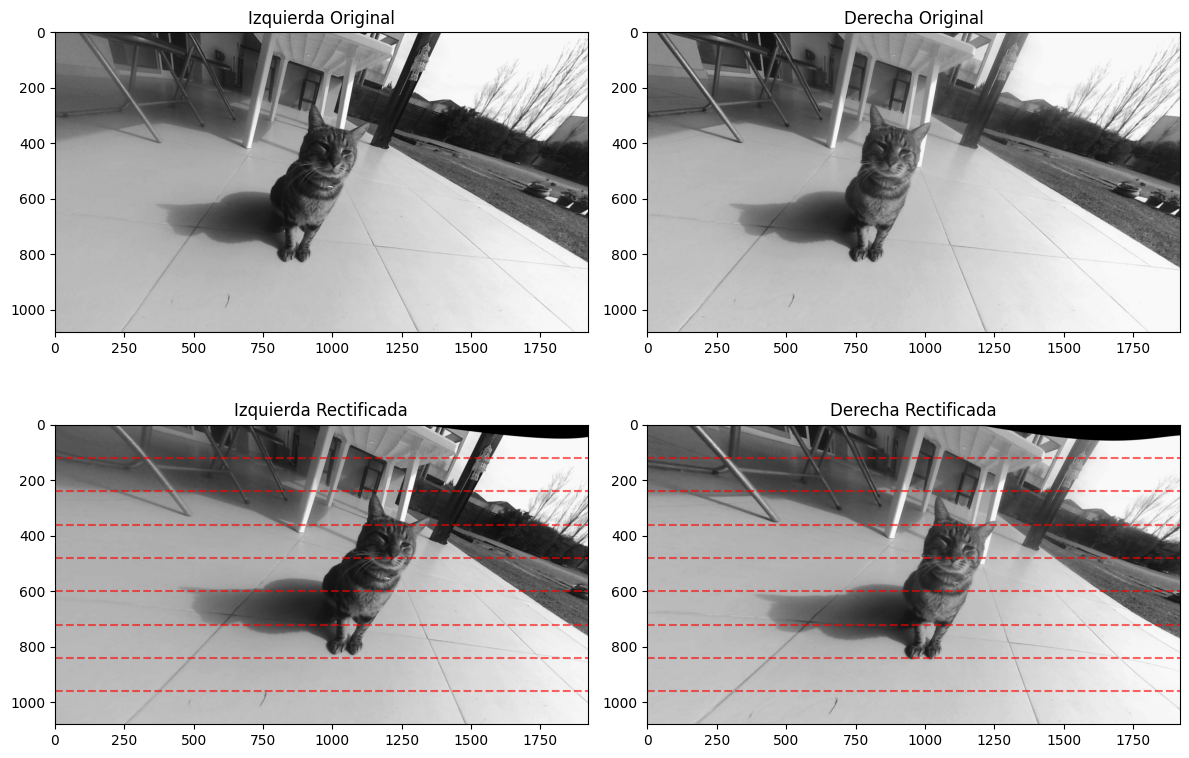

In [15]:
# Calcular mapas de rectificación
R1, R2, P1, P2, Q, roi1, roi2 = cv.stereoRectify(K1, D1, K2, D2, image_size, R, t)

map1x, map1y = cv.initUndistortRectifyMap(K1, D1, R1, P1, image_size, cv.CV_32FC1)
map2x, map2y = cv.initUndistortRectifyMap(K2, D2, R2, P2, image_size, cv.CV_32FC1)

# Leer un par original y aplicar remap
img_left = cv.imread('../data/examples/stereodemo/left_0.jpg', cv.IMREAD_COLOR)
img_right = cv.imread('../data/examples/stereodemo/right_0.jpg', cv.IMREAD_COLOR)

rect_left = cv.remap(img_left, map1x, map1y, cv.INTER_LINEAR)
rect_right = cv.remap(img_right, map2x, map2y, cv.INTER_LINEAR)

# Visualización comparativa
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Fila 1: Originales
axs[0, 0].imshow(cv.cvtColor(img_left, cv.COLOR_BGR2RGB))
axs[0, 0].set_title("Izquierda Original")
axs[0, 1].imshow(cv.cvtColor(img_right, cv.COLOR_BGR2RGB))
axs[0, 1].set_title("Derecha Original")

# Fila 2: Rectificadas con líneas epipolares
axs[1, 0].imshow(cv.cvtColor(rect_left, cv.COLOR_BGR2RGB))
axs[1, 0].set_title("Izquierda Rectificada")
axs[1, 1].imshow(cv.cvtColor(rect_right, cv.COLOR_BGR2RGB))
axs[1, 1].set_title("Derecha Rectificada")

# Dibujar líneas horizontales de prueba en las imágenes rectificadas
line_y_positions = np.linspace(0, image_size[1], 10)[1:-1]
for y in line_y_positions:
    axs[1, 0].axhline(y, color='r', linestyle='--', alpha=0.6)
    axs[1, 1].axhline(y, color='r', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()